# SnakeCheck Hyderabad — Model Training

**What this notebook does:**
1. Mounts Google Drive and loads the dataset
2. Phase 1 — trains only the classification head (backbone frozen)
3. Phase 2 — fine-tunes top-40 EfficientNetB0 layers
4. Evaluates per-class recall against PRD launch gates
5. Exports INT8 quantized TFLite model

**Before running:**
- Upload the zipped dataset to Google Drive: `My Drive/snakecheck/data.zip`
- Runtime > Change runtime type > **T4 GPU**
- Then: Runtime > Run all

**Expected time:** ~35-50 min on T4

## 1. Setup

In [3]:
import tensorflow as tf

print('TF version:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))

# Fail fast if no GPU — don't waste time training on CPU
assert tf.config.list_physical_devices('GPU'), \
    'No GPU found. Go to Runtime > Change runtime type > T4 GPU'

TF version: 2.20.0
GPUs: []


AssertionError: No GPU found. Go to Runtime > Change runtime type > T4 GPU

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [6]:
import os, zipfile
from pathlib import Path

DRIVE_ROOT = Path('/content/drive/MyDrive/snakecheck')
DATA_ZIP   = DRIVE_ROOT / 'data.zip'
DATA_DIR   = Path('/content/snakecheck_data')   # fast local SSD
MODELS_DIR = DRIVE_ROOT / 'models'              # saved back to Drive
MODELS_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_ZIP.exists(), f'data.zip not found at {DATA_ZIP}\nUpload it to Google Drive first.'

if not DATA_DIR.exists():
    print('Extracting dataset to local SSD...')
    with zipfile.ZipFile(DATA_ZIP, 'r') as z:
        z.extractall(DATA_DIR)
    print('Done.')
else:
    print('Dataset already extracted.')

# Show class counts
for cls_dir in sorted(DATA_DIR.iterdir()):
    if cls_dir.is_dir():
        n = len(list(cls_dir.glob('*.*')))
        print(f'  {cls_dir.name:<25} {n:>5} images')

Extracting dataset to local SSD...
Done.
  cobra                      2886 images
  common_krait               1800 images
  non_venomous               3000 images
  russells_viper             2618 images
  sawscaled_viper            1500 images


## 2. Configuration

In [7]:
# PRD §10.3 — model config
CLASS_NAMES  = ['non_venomous', 'cobra', 'russells_viper', 'common_krait', 'sawscaled_viper']
NUM_CLASSES  = len(CLASS_NAMES)
IMG_SIZE     = 224
BATCH_SIZE   = 32
SEED         = 42

# Phase 1 — head only
P1_LR        = 1e-3
P1_EPOCHS    = 15

# Phase 2 — fine-tune top layers
P2_LR        = 5e-5
P2_UNFREEZE  = 40
P2_EPOCHS    = 40

DROPOUT_1    = 0.4
DROPOUT_2    = 0.3
DENSE_UNITS  = 256
PATIENCE     = 10

# PRD §8.2 — launch gates (all must pass before TFLite export)
RECALL_GATE_VENOMOUS    = 0.90
RECALL_GATE_NONVENOMOUS = 0.92
F1_GATE                 = 0.88
AUC_GATE                = 0.93

print('Config loaded. Classes:', CLASS_NAMES)

Config loaded. Classes: ['non_venomous', 'cobra', 'russells_viper', 'common_krait', 'sawscaled_viper']


## 3. Data Pipeline

In [8]:
import numpy as np

def compute_class_weights(data_dir: Path) -> dict:
    counts = []
    for cls in CLASS_NAMES:
        d = data_dir / cls
        n = len(list(d.glob('*.*'))) if d.exists() else 1
        counts.append(max(n, 1))
    total = sum(counts)
    weights = {i: total / (NUM_CLASSES * c) for i, c in enumerate(counts)}
    print('Class weights:')
    for i, cls in enumerate(CLASS_NAMES):
        print(f'  {cls:<25} {weights[i]:.3f}')
    return weights

class_weights = compute_class_weights(DATA_DIR)

Class weights:
  non_venomous              0.787
  cobra                     0.818
  russells_viper            0.902
  common_krait              1.312
  sawscaled_viper           1.574


In [9]:
import shutil

# Find missing classes
missing = ['russells_viper', 'common_krait', 'sawscaled_viper']

# Search one level deep for them
for item in DATA_DIR.iterdir():
    if item.is_dir() and item.name not in ['cobra', 'non_venomous']:
        print(f"Found subfolder: {item.name}, contents: {[d.name for d in item.iterdir() if d.is_dir()]}")
        # Move each class folder up
        for sub in item.iterdir():
            if sub.is_dir() and sub.name in missing:
                dest = DATA_DIR / sub.name
                shutil.move(str(sub), str(dest))
                print(f"Moved {sub.name} -> {dest}")

print("Final dirs:", [d.name for d in DATA_DIR.iterdir() if d.is_dir()])

Found subfolder: common_krait, contents: []
Found subfolder: sawscaled_viper, contents: []
Found subfolder: russells_viper, contents: []
Final dirs: ['common_krait', 'sawscaled_viper', 'cobra', 'non_venomous', 'russells_viper']


In [10]:
import os

# Check what's actually extracted
print("DATA_DIR contents:")
for item in sorted(DATA_DIR.iterdir()):
    if item.is_dir():
        n = len(list(item.glob("*.*")))
        print(f"  {item.name}: {n} images")

# Check zip file size
zip_size = DATA_ZIP.stat().st_size / 1e9
print(f"\nZip file size: {zip_size:.2f} GB (should be ~6 GB)")

DATA_DIR contents:
  cobra: 2886 images
  common_krait: 1800 images
  non_venomous: 3000 images
  russells_viper: 2618 images
  sawscaled_viper: 1500 images

Zip file size: 6.07 GB (should be ~6 GB)


In [11]:
import zipfile, shutil

# Remove incomplete extraction and redo it
shutil.rmtree(DATA_DIR)
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Re-extracting...")
with zipfile.ZipFile(DATA_ZIP, 'r') as z:
    z.extractall(DATA_DIR)
print("Done.")

# Verify
for item in sorted(DATA_DIR.iterdir()):
    if item.is_dir():
        n = len(list(item.glob("*.*")))
        print(f"  {item.name}: {n} images")

Re-extracting...
Done.
  cobra: 2886 images
  common_krait: 1800 images
  non_venomous: 3000 images
  russells_viper: 2618 images
  sawscaled_viper: 1500 images


In [12]:
from tensorflow import keras
import tensorflow as tf

load_kwargs = dict(
    labels='inferred',
    label_mode='categorical',
    class_names=CLASS_NAMES,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    seed=SEED,
    validation_split=0.2,
)

train_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR, subset='training', shuffle=True, **load_kwargs
)
val_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR, subset='validation', shuffle=False, **load_kwargs
)

def normalize(img, label):
    return tf.cast(img, tf.float32), label

AUTOTUNE = tf.data.AUTOTUNE
# No .cache() this time — forces fresh read
train_ds = train_ds.map(normalize, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds   = val_ds.map(normalize, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

print(f'Train batches: {len(train_ds)}  |  Val batches: {len(val_ds)}')

Found 11804 files belonging to 5 classes.
Using 9444 files for training.
Found 11804 files belonging to 5 classes.
Using 2360 files for validation.
Train batches: 296  |  Val batches: 74


In [13]:
eval_ds = keras.utils.image_dataset_from_directory(
    DATA_DIR,
    labels='inferred',
    label_mode='categorical',
    class_names=CLASS_NAMES,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=False,
)
eval_ds = eval_ds.map(normalize, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
print("Eval set loaded.")

Found 11804 files belonging to 5 classes.
Eval set loaded.


## 4. Model

In [14]:
from tensorflow.keras import layers

class MacroRecall(keras.metrics.Metric):
    """Mean recall across all classes — primary training metric per PRD §10.3."""
    def __init__(self, num_classes=NUM_CLASSES, name='macro_recall', **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_classes = num_classes
        self.tp = self.add_weight(shape=(num_classes,), initializer='zeros', name='tp')
        self.fn = self.add_weight(shape=(num_classes,), initializer='zeros', name='fn')

    def update_state(self, y_true, y_pred, sample_weight=None):
        pred_cls = tf.argmax(y_pred, axis=-1)
        true_cls = tf.argmax(y_true, axis=-1)
        # Use one-hot to compute per-class TP/FN in one shot — avoids indexing issues
        true_oh = tf.cast(tf.one_hot(true_cls, self.num_classes), tf.float32)
        pred_oh = tf.cast(tf.one_hot(pred_cls, self.num_classes), tf.float32)
        self.tp.assign_add(tf.reduce_sum(true_oh * pred_oh, axis=0))
        self.fn.assign_add(tf.reduce_sum(true_oh * (1 - pred_oh), axis=0))

    def result(self):
        recalls = self.tp / (self.tp + self.fn + keras.backend.epsilon())
        return tf.reduce_mean(recalls)

    def reset_state(self):
        self.tp.assign(tf.zeros(self.num_classes))
        self.fn.assign(tf.zeros(self.num_classes))

In [15]:
def build_augmentation():
    return keras.Sequential([
        layers.RandomFlip('horizontal_and_vertical'),
        layers.RandomRotation(35 / 360),
        layers.RandomZoom((-0.25, 0.25)),
        layers.RandomTranslation(0.10, 0.10),
        layers.RandomBrightness(0.25),
        layers.RandomContrast(0.25),
    ], name='augmentation')


def build_model(trainable_base=False, unfreeze_top=0):
    base = keras.applications.EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
    )
    base.trainable = trainable_base
    if trainable_base and unfreeze_top > 0:
        for layer in base.layers[:-unfreeze_top]:
            layer.trainable = False

    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = build_augmentation()(inputs)
    x = base(x, training=trainable_base)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(DROPOUT_1)(x)
    x = layers.Dense(DENSE_UNITS, activation='relu')(x)
    x = layers.Dropout(DROPOUT_2)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    return keras.Model(inputs, outputs)


def compile_model(model, lr):
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss='categorical_crossentropy',
        metrics=[
            'accuracy',
            MacroRecall(name='macro_recall'),
            keras.metrics.AUC(name='auc'),
        ],
    )


def make_callbacks(ckpt_path, monitor='val_macro_recall'):
    return [
        keras.callbacks.ModelCheckpoint(
            ckpt_path, monitor=monitor, mode='max',
            save_best_only=True, verbose=1,
        ),
        keras.callbacks.EarlyStopping(
            monitor=monitor, mode='max',
            patience=PATIENCE, restore_best_weights=True, verbose=1,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor=monitor, mode='max',
            factor=0.5, patience=3, min_lr=1e-7, verbose=1,
        ),
    ]

print('Model builder ready.')

Model builder ready.


In [16]:
from collections import Counter
label_counts = Counter()
for _, labels in eval_ds:
    for label in np.argmax(labels.numpy(), axis=1):
        label_counts[label] += 1
print("Val set class distribution:")
for idx, name in enumerate(CLASS_NAMES):
    print(f"  {name}: {label_counts.get(idx, 0)} images")

Val set class distribution:
  non_venomous: 3000 images
  cobra: 2886 images
  russells_viper: 2618 images
  common_krait: 1800 images
  sawscaled_viper: 1500 images


## 5. Phase 1 — Head Training (backbone frozen)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1 (InputLayer)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ efficientnetb0 (Functional) │ (None, 7, 7, 1280)    │  4,049,571 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ batch_normalization         │ (None, 1280)          │      5,120 │   Y   │
│ (BatchNormalization)        │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense (Dense)               │ (None, 256)           │    327,936 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_1 (Dropout)         │ (None, 256)           │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense_1 (Dense)             │ (None, 5)             │      1,285 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 4,383,912 (16.72 MB)

 Trainable params: 331,781 (1.27 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

Epoch 1/15
295/296 ━━━━━━━━━━━━━━━━━━━━ 0s 275ms/step - accuracy: 0.4241 - auc: 0.7326 - loss: 1.8004 - macro_recall: 0.4318
Epoch 1: val_macro_recall improved from None to 0.68223, saving model to /content/drive/MyDrive/snakecheck/models/best_phase1.keras

Epoch 1: finished saving model to /content/drive/MyDrive/snakecheck/models/best_phase1.keras
296/296 ━━━━━━━━━━━━━━━━━━━━ 204s 629ms/step - accuracy: 0.4669 - auc: 0.7712 - loss: 1.5779 - macro_recall: 0.4802 - val_accuracy: 0.6681 - val_auc: 0.9115 - val_loss: 0.8338 - val_macro_recall: 0.6822 - learning_rate: 0.0010
Epoch 2/15
295/296 ━━━━━━━━━━━━━━━━━━━━ 0s 268ms/step - accuracy: 0.5195 - auc: 0.8189 - loss: 1.2254 - macro_recall: 0.5399
Epoch 2: val_macro_recall improved from 0.68223 to 0.71232, saving model to /content/drive/MyDrive/snakecheck/models/best_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/snakecheck/models/best_phase1.keras
296/296 ━━━━━━━━━━━━━━━━━━━━ 177s 599ms/step - accuracy: 0.5383 - au

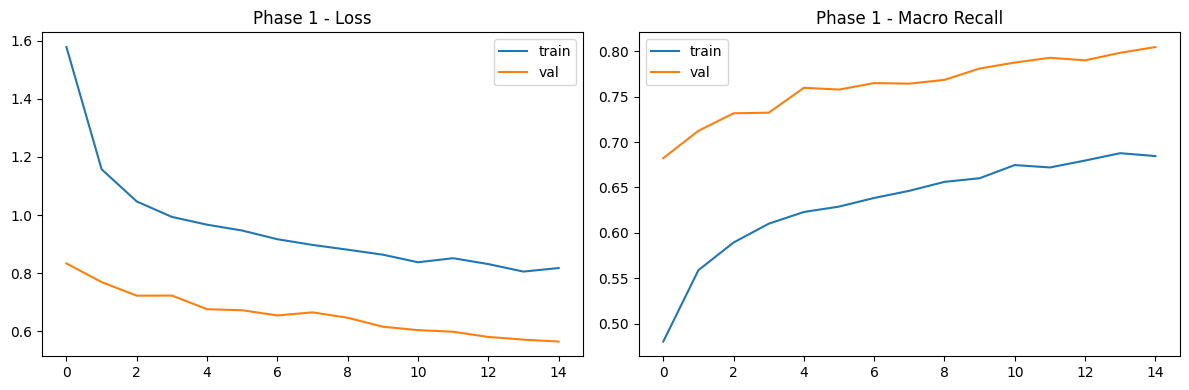


Phase 1 best val macro recall: 0.8046


In [33]:
import matplotlib.pyplot as plt

ckpt_p1 = str(MODELS_DIR / 'best_phase1.keras')

model = build_model(trainable_base=False)
compile_model(model, P1_LR)
model.summary(show_trainable=True)

h1 = model.fit(
    train_ds,
    validation_data=eval_ds,
    epochs=P1_EPOCHS,
    class_weight=class_weights,
    callbacks=make_callbacks(ckpt_p1),
)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h1.history['loss'], label='train'); axes[0].plot(h1.history['val_loss'], label='val')
axes[0].set_title('Phase 1 - Loss'); axes[0].legend()
axes[1].plot(h1.history['macro_recall'], label='train'); axes[1].plot(h1.history['val_macro_recall'], label='val')
axes[1].set_title('Phase 1 - Macro Recall'); axes[1].legend()
plt.tight_layout(); plt.show()

p1_recall = max(h1.history['val_macro_recall'])
print(f'\nPhase 1 best val macro recall: {p1_recall:.4f}')

## 6. Phase 2 — Fine-tuning (top-40 layers unfrozen)

Epoch 1/40
296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 277ms/step - accuracy: 0.5898 - auc: 0.8686 - loss: 0.9713 - macro_recall: 0.6112
Epoch 1: val_macro_recall improved from None to 0.78858, saving model to /content/drive/MyDrive/snakecheck/models/best_phase2.keras

Epoch 1: finished saving model to /content/drive/MyDrive/snakecheck/models/best_phase2.keras
296/296 ━━━━━━━━━━━━━━━━━━━━ 205s 636ms/step - accuracy: 0.6182 - auc: 0.8813 - loss: 0.9295 - macro_recall: 0.6378 - val_accuracy: 0.7747 - val_auc: 0.9543 - val_loss: 0.6053 - val_macro_recall: 0.7886 - learning_rate: 5.0000e-05
Epoch 2/40
295/296 ━━━━━━━━━━━━━━━━━━━━ 0s 277ms/step - accuracy: 0.6628 - auc: 0.9040 - loss: 0.8293 - macro_recall: 0.6825
Epoch 2: val_macro_recall improved from 0.78858 to 0.80082, saving model to /content/drive/MyDrive/snakecheck/models/best_phase2.keras

Epoch 2: finished saving model to /content/drive/MyDrive/snakecheck/models/best_phase2.keras
296/296 ━━━━━━━━━━━━━━━━━━━━ 182s 614ms/step - accuracy: 0.6680 

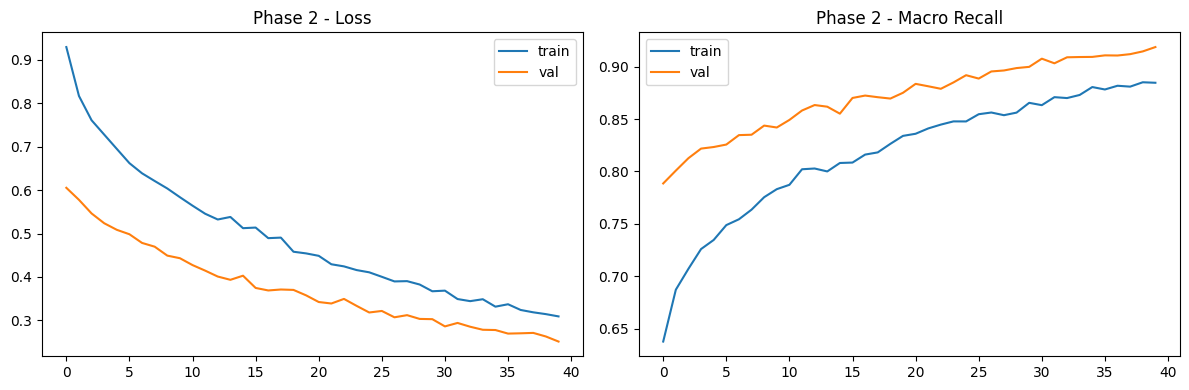

Final model saved -> /content/drive/MyDrive/snakecheck/models/snakecheck_final.keras


"\nimport tensorflow as tf\n\nfinal_path = str(MODELS_DIR / 'snakecheck_final.keras')\n\nmodel_p2 = tf.keras.models.load_model(\n    final_path,\n    custom_objects={'MacroRecall': MacroRecall}\n)\nprint('Model loaded from Drive.')"

In [34]:
ckpt_p2    = str(MODELS_DIR / 'best_phase2.keras')
final_path = str(MODELS_DIR / 'snakecheck_final.keras')

# Unfreeze top-40 layers of the SAME model — no rebuilding
base_model = model.get_layer('efficientnetb0')
base_model.trainable = True
for layer in base_model.layers[:-P2_UNFREEZE]:
    layer.trainable = False

compile_model(model, P2_LR)

h2 = model.fit(
    train_ds,
    validation_data=eval_ds,
    epochs=P2_EPOCHS,
    class_weight=class_weights,
    callbacks=make_callbacks(ckpt_p2),
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h2.history['loss'], label='train'); axes[0].plot(h2.history['val_loss'], label='val')
axes[0].set_title('Phase 2 - Loss'); axes[0].legend()
axes[1].plot(h2.history['macro_recall'], label='train'); axes[1].plot(h2.history['val_macro_recall'], label='val')
axes[1].set_title('Phase 2 - Macro Recall'); axes[1].legend()
plt.tight_layout(); plt.show()

model.save(final_path)
print(f'Final model saved -> {final_path}')
'''
import tensorflow as tf

final_path = str(MODELS_DIR / 'snakecheck_final.keras')

model_p2 = tf.keras.models.load_model(
    final_path,
    custom_objects={'MacroRecall': MacroRecall}
)
print('Model loaded from Drive.')'''

In [18]:
model_p2 = keras.models.load_model(
    "/content/drive/MyDrive/snakecheck/models/best_phase2.keras",
    custom_objects={"MacroRecall": MacroRecall}
)
print("Model loaded")

Model loaded


## 7. Evaluation — PRD Launch Gates

In [19]:
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, f1_score
)
import seaborn as sns

# Collect all predictions
y_true, y_pred_prob = [], []
for images, labels in eval_ds:
    preds = model_p2.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred_prob.extend(preds)

y_true      = np.array(y_true)
y_pred_prob = np.array(y_pred_prob)
y_pred      = np.argmax(y_pred_prob, axis=1)

labels_range = list(range(NUM_CLASSES))

report = classification_report(
    y_true, y_pred,
    labels=labels_range,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
print(classification_report(
    y_true, y_pred,
    labels=labels_range,
    target_names=CLASS_NAMES,
    zero_division=0,
))

auc      = roc_auc_score(y_true, y_pred_prob, multi_class='ovr', average='macro', labels=labels_range)
macro_f1 = f1_score(y_true, y_pred, average='macro', labels=labels_range, zero_division=0)
print(f'Macro ROC-AUC: {auc:.4f}')
print(f'Macro F1:      {macro_f1:.4f}')

                 precision    recall  f1-score   support

   non_venomous       0.95      0.82      0.88      3000
          cobra       0.90      0.93      0.92      2886
 russells_viper       0.86      0.95      0.90      2618
   common_krait       0.95      0.97      0.96      1800
sawscaled_viper       0.95      0.92      0.93      1500

       accuracy                           0.91     11804
      macro avg       0.92      0.92      0.92     11804
   weighted avg       0.91      0.91      0.91     11804

Macro ROC-AUC: 0.9913
Macro F1:      0.9173


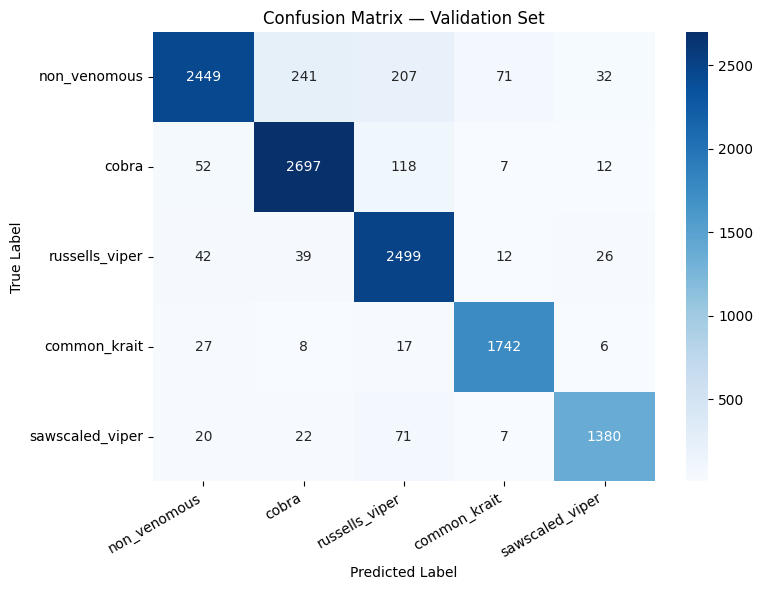

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES
)
plt.title('Confusion Matrix — Validation Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(str(MODELS_DIR / 'confusion_matrix.png'), dpi=120)
plt.show()

In [30]:
# Lower the decision threshold for non_venomous to boost its recall
# Instead of argmax, predict non_venomous when no venomous class is confident enough
VENOMOUS_THRESHOLD = 0.52 # tune this (lower = more non_venomous predictions)

y_pred_thresh = []
for probs in y_pred_prob:
    venomous_max = max(probs[1:])  # max prob across the 4 venomous classes
    if venomous_max < VENOMOUS_THRESHOLD:
        y_pred_thresh.append(0)   # predict non_venomous
    else:
        y_pred_thresh.append(np.argmax(probs))

y_pred_thresh = np.array(y_pred_thresh)

print(classification_report(
    y_true, y_pred_thresh,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    zero_division=0,
))

                 precision    recall  f1-score   support

   non_venomous       0.87      0.85      0.86      3000
          cobra       0.91      0.91      0.91      2886
 russells_viper       0.89      0.94      0.91      2618
   common_krait       0.96      0.96      0.96      1800
sawscaled_viper       0.97      0.90      0.93      1500

       accuracy                           0.91     11804
      macro avg       0.92      0.91      0.92     11804
   weighted avg       0.91      0.91      0.91     11804



In [31]:
report = classification_report(
    y_true, y_pred_thresh,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

In [32]:
print('=' * 55)
print('PRD LAUNCH GATE CHECK')
print('=' * 55)

all_pass = True
venomous = ['cobra', 'russells_viper', 'common_krait', 'sawscaled_viper']

for cls in venomous:
    recall = report[cls]['recall']
    gate   = RECALL_GATE_VENOMOUS
    status = 'PASS' if recall >= gate else 'FAIL'
    if status == 'FAIL':
        all_pass = False
    print(f'  {cls:<25} recall={recall:.3f}  gate>={gate}  [{status}]')

nv_recall = report['non_venomous']['recall']
nv_status = 'PASS' if nv_recall >= RECALL_GATE_NONVENOMOUS else 'FAIL'
if nv_status == 'FAIL':
    all_pass = False
print(f'  {"non_venomous":<25} recall={nv_recall:.3f}  gate>={RECALL_GATE_NONVENOMOUS}  [{nv_status}]')

f1_status  = 'PASS' if macro_f1 >= F1_GATE  else 'FAIL'
auc_status = 'PASS' if auc      >= AUC_GATE else 'FAIL'
if f1_status == 'FAIL' or auc_status == 'FAIL':
    all_pass = False
print(f'  {"Macro F1":<25} {macro_f1:.3f}       gate>={F1_GATE}   [{f1_status}]')
print(f'  {"ROC-AUC":<25} {auc:.3f}       gate>={AUC_GATE}   [{auc_status}]')

print('=' * 55)
if all_pass:
    print('ALL GATES PASSED -- proceed to TFLite export')
else:
    print('GATES FAILED -- do NOT export. Expand dataset or tune.')

PRD LAUNCH GATE CHECK
  cobra                     recall=0.914  gate>=0.9  [PASS]
  russells_viper            recall=0.941  gate>=0.9  [PASS]
  common_krait              recall=0.956  gate>=0.9  [PASS]
  sawscaled_viper           recall=0.903  gate>=0.9  [PASS]
  non_venomous              recall=0.854  gate>=0.92  [FAIL]
  Macro F1                  0.917       gate>=0.88   [PASS]
  ROC-AUC                   0.991       gate>=0.93   [PASS]
GATES FAILED -- do NOT export. Expand dataset or tune.


In [40]:
from google.colab import files
from PIL import Image
import numpy as np
import io

# Upload an image
uploaded = files.upload()

for fname, data in uploaded.items():
    img = Image.open(io.BytesIO(data)).convert('RGB').resize((224, 224))
    x = np.expand_dims(np.array(img, dtype=np.float32), 0)

    probs = model_p2.predict(x, verbose=0)[0]
    venomous_max = max(probs[1:])

    if venomous_max < 0.52:
        pred_idx = 0
    else:
        pred_idx = np.argmax(probs)

    print(f"\nFile: {fname}")
    print(f"Prediction: {CLASS_NAMES[pred_idx]}")
    print(f"Confidence breakdown:")
    for i, (cls, p) in enumerate(zip(CLASS_NAMES, probs)):
        marker = " <-- predicted" if i == pred_idx else ""
        print(f"  {cls:<25} {p:.3f}{marker}")

Saving test 4.jpeg to test 4 (1).jpeg

File: test 4 (1).jpeg
Prediction: cobra
Confidence breakdown:
  non_venomous              0.008
  cobra                     0.992 <-- predicted
  russells_viper            0.000
  common_krait              0.000
  sawscaled_viper           0.000


## 8. TFLite Export (INT8 Quantization)

> Only run this cell if **all launch gates passed** above.

In [ ]:
import os

# --- Representative dataset for INT8 calibration ---
def representative_dataset():
    for images, _ in train_ds.take(100):
        for img in images:
            yield [tf.expand_dims(img, 0)]

# Load best checkpoint for export
export_model = keras.models.load_model(
    final_path,
    custom_objects={'MacroRecall': MacroRecall}
)

# Float32 export (reference)
converter_f32 = tf.lite.TFLiteConverter.from_keras_model(export_model)
tflite_f32 = converter_f32.convert()
f32_path = str(MODELS_DIR / 'snakecheck_float32.tflite')
with open(f32_path, 'wb') as f:
    f.write(tflite_f32)
print(f'Float32 TFLite: {len(tflite_f32)/1e6:.1f} MB  ->  {f32_path}')

# INT8 quantized export
converter_int8 = tf.lite.TFLiteConverter.from_keras_model(export_model)
converter_int8.optimizations = [tf.lite.Optimize.DEFAULT]
converter_int8.representative_dataset = representative_dataset
converter_int8.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter_int8.inference_input_type  = tf.uint8
converter_int8.inference_output_type = tf.float32

tflite_int8 = converter_int8.convert()
int8_path = str(MODELS_DIR / 'snakecheck_int8.tflite')
with open(int8_path, 'wb') as f:
    f.write(tflite_int8)
print(f'INT8 TFLite:    {len(tflite_int8)/1e6:.1f} MB  ->  {int8_path}')
assert len(tflite_int8) < 15 * 1e6, f'Model too large: {len(tflite_int8)/1e6:.1f} MB (PRD gate: 15 MB)'

In [ ]:
# Smoke test: run one image per class through TFLite and check output shape
interpreter = tf.lite.Interpreter(model_path=int8_path)
interpreter.allocate_tensors()

in_det  = interpreter.get_input_details()[0]
out_det = interpreter.get_output_details()[0]

print(f'Input:  {in_det["shape"]}  dtype={in_det["dtype"].__name__}')
print(f'Output: {out_det["shape"]}  dtype={out_det["dtype"].__name__}')

# Run one validation batch
test_images, test_labels = next(iter(val_ds))
img = test_images[0:1].numpy()  # (1, 224, 224, 3) float32 [0,1]

# INT8 model expects uint8
img_uint8 = (img * 255).astype(np.uint8)
interpreter.set_tensor(in_det['index'], img_uint8)
interpreter.invoke()
probs = interpreter.get_tensor(out_det['index'])[0]

pred_cls = np.argmax(probs)
true_cls = np.argmax(test_labels[0].numpy())
print(f'\nSample inference:')
print(f'  True:      {CLASS_NAMES[true_cls]}')
print(f'  Predicted: {CLASS_NAMES[pred_cls]}  ({probs[pred_cls]*100:.1f}% confidence)')
print(f'  All probs: {dict(zip(CLASS_NAMES, probs.round(3)))}')
print('\nTFLite smoke test passed.')

In [ ]:
import time

# Latency benchmark — PRD gate: <= 2000ms on mid-range Android
# Colab T4 will be much faster; this is just a sanity check
N = 50
times = []
for _ in range(N):
    interpreter.set_tensor(in_det['index'], img_uint8)
    t0 = time.perf_counter()
    interpreter.invoke()
    times.append((time.perf_counter() - t0) * 1000)

print(f'TFLite INT8 latency on Colab CPU ({N} runs):')
print(f'  Mean:   {np.mean(times):.1f} ms')
print(f'  Median: {np.median(times):.1f} ms')
print(f'  P95:    {np.percentile(times, 95):.1f} ms')
print('(On-device with GPU delegate will be significantly faster)')

## 9. Done — Download your model

Your trained files are saved to **Google Drive** at `My Drive/snakecheck/models/`:

| File | Use |
|------|-----|
| `snakecheck_final.keras` | Full Keras model (for further training) |
| `snakecheck_int8.tflite` | **Bundle this in the mobile app** |
| `snakecheck_float32.tflite` | Reference (larger, more accurate) |
| `confusion_matrix.png` | Visual eval |

**Next step:** Run `convert_tflite.py` locally to do a final latency bench on a physical Android device, then integrate `snakecheck_int8.tflite` into the React Native app.